In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

In [6]:
DATA_DIR = Path("../data")
OUTPUT_DIR = Path("../plots")

OUTPUT_DIR.mkdir(exist_ok=True)

In [7]:
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

target = "SalePrice"

In [8]:
print(f"Training rows/columns: {train.shape}")
print(f"Test rows/columns: {test.shape}")

print(f"Duplicate training rows: {train.duplicated().sum()}")

Training rows/columns: (1460, 81)
Test rows/columns: (1459, 80)
Duplicate training rows: 0


In [9]:
print("Target summary:")
display(train[target].describe().round(2))

print(f"Skewness: {train[target].skew():.3f}")

Target summary:


count      1460.0
mean     180921.2
std       79442.5
min       34900.0
25%      129975.0
50%      163000.0
75%      214000.0
max      755000.0
Name: SalePrice, dtype: float64

Skewness: 1.883


In [10]:
missing = train.isna().sum().sort_values(ascending=False)

print("Columns with most missing training values:")

display(missing[missing.gt(0)].head(15))

Columns with most missing training values:


PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageQual        81
GarageFinish      81
GarageType        81
GarageYrBlt       81
GarageCond        81
BsmtFinType2      38
BsmtExposure      38
BsmtCond          37
dtype: int64

In [11]:
numeric = train.select_dtypes(include="number")

correlations = (
    numeric.corr()[target]
    .drop(target)
    .sort_values(ascending=False)
)

print("Strongest numeric correlations with SalePrice:")
display(correlations.head(10).round(3))

print("Most negative numeric correlations with SalePrice:")
display(correlations.tail(5).round(3))

Strongest numeric correlations with SalePrice:


OverallQual     0.791
GrLivArea       0.709
GarageCars      0.640
GarageArea      0.623
TotalBsmtSF     0.614
1stFlrSF        0.606
FullBath        0.561
TotRmsAbvGrd    0.534
YearBuilt       0.523
YearRemodAdd    0.507
Name: SalePrice, dtype: float64

Most negative numeric correlations with SalePrice:


YrSold          -0.029
OverallCond     -0.078
MSSubClass      -0.084
EnclosedPorch   -0.129
KitchenAbvGr    -0.136
Name: SalePrice, dtype: float64

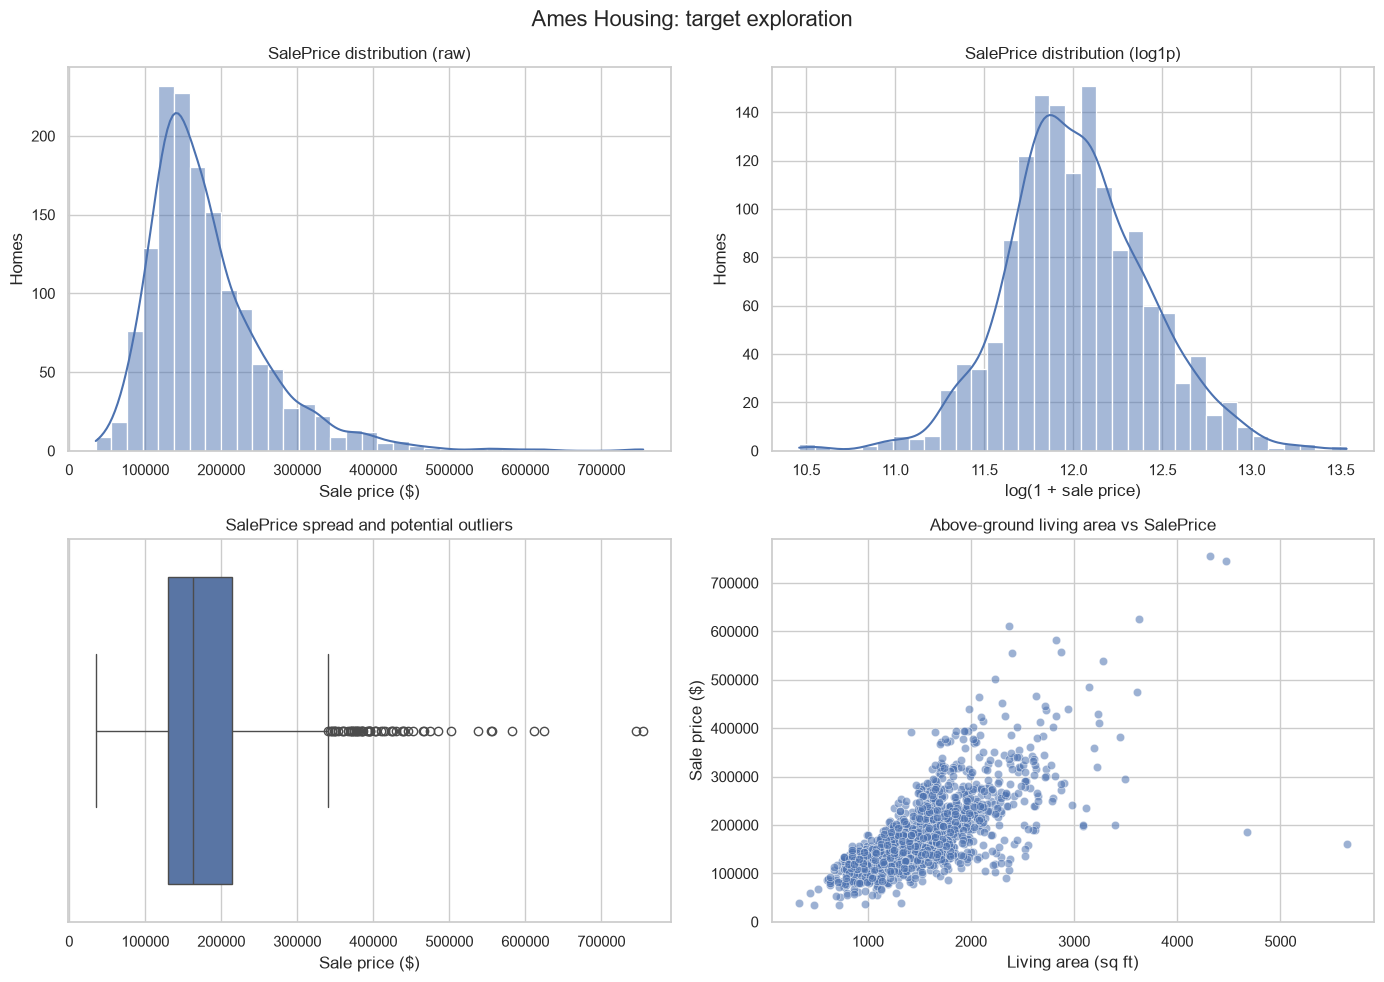

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(
    train[target],
    bins=35,
    kde=True,
    ax=axes[0, 0]
)
axes[0, 0].set(
    title="SalePrice distribution (raw)",
    xlabel="Sale price ($)",
    ylabel="Homes"
)

sns.histplot(
    np.log1p(train[target]),
    bins=35,
    kde=True,
    ax=axes[0, 1]
)
axes[0, 1].set(
    title="SalePrice distribution (log1p)",
    xlabel="log(1 + sale price)",
    ylabel="Homes"
)

sns.boxplot(
    x=train[target],
    ax=axes[1, 0]
)
axes[1, 0].set(
    title="SalePrice spread and potential outliers",
    xlabel="Sale price ($)"
)

sns.scatterplot(
    data=train,
    x="GrLivArea",
    y=target,
    alpha=.55,
    ax=axes[1, 1]
)
axes[1, 1].set(
    title="Above-ground living area vs SalePrice",
    xlabel="Living area (sq ft)",
    ylabel="Sale price ($)"
)

fig.suptitle("Ames Housing: target exploration", fontsize=16)
fig.tight_layout()

plt.savefig(
    OUTPUT_DIR / "saleprice_exploration.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

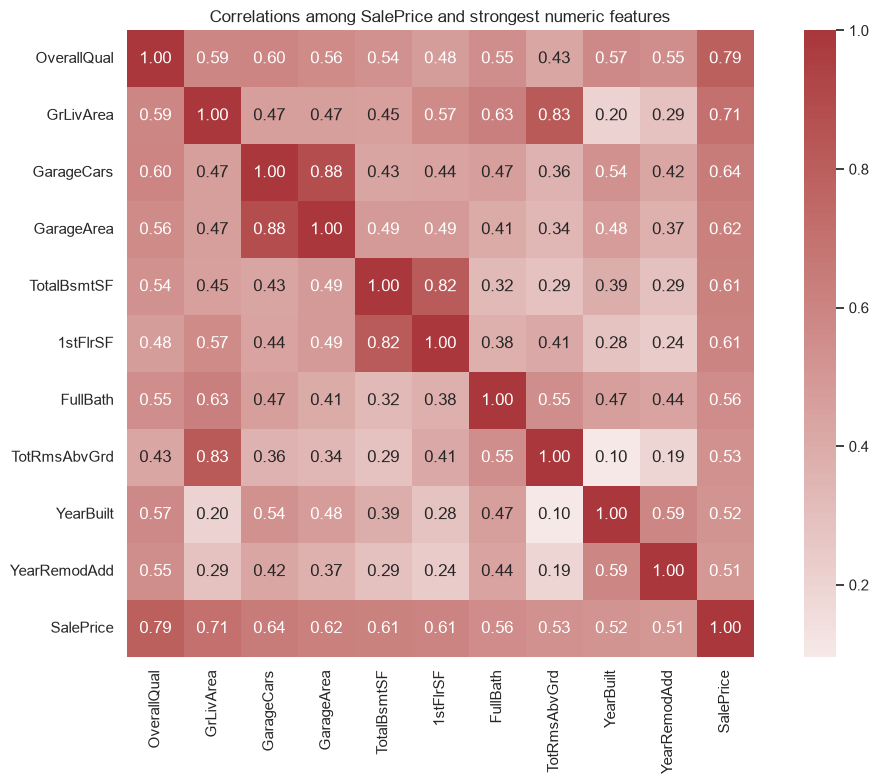

In [13]:
top = correlations.head(10).index.tolist()

plt.figure(figsize=(11, 8))

sns.heatmap(
    train[top + [target]].corr(),
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    square=True
)

plt.title("Correlations among SalePrice and strongest numeric features")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "saleprice_correlations.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()